In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bank-full.csv", sep=";")

print("Dataset shape:", df.shape)
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

display(df.head())
display(df.describe(include="all").T)

Dataset shape: (45211, 17)
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate rows: 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [2]:
bank = df.copy()

bank["subscribed"] = bank["y"].map({"yes": 1, "no": 0})

print("Subscription rate:", round(bank["subscribed"].mean() * 100, 2), "%")
print("Successful subscriptions:", (bank["y"] == "yes").sum())
print("Unsuccessful contacts:", (bank["y"] == "no").sum())

print("\nSubscription rate by job:")
display(
    (bank.groupby("job")["subscribed"].mean() * 100)
    .sort_values(ascending=False).round(2)
)

print("\nSubscription rate by education:")
display(
    (bank.groupby("education")["subscribed"].mean() * 100)
    .sort_values(ascending=False).round(2)
)

print("\nSubscription rate by contact method:")
display(
    (bank.groupby("contact")["subscribed"].mean() * 100)
    .sort_values(ascending=False).round(2)
)

print("\nSubscription rate by month:")
display(
    (bank.groupby("month")["subscribed"].mean() * 100)
    .sort_values(ascending=False).round(2)
)

Subscription rate: 11.7 %
Successful subscriptions: 5289
Unsuccessful contacts: 39922

Subscription rate by job:


job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: subscribed, dtype: float64


Subscription rate by education:


education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: subscribed, dtype: float64


Subscription rate by contact method:


contact
cellular     14.92
telephone    13.42
unknown       4.07
Name: subscribed, dtype: float64


Subscription rate by month:


month
mar    51.99
dec    46.73
sep    46.46
oct    43.77
apr    19.68
feb    16.65
aug    11.01
jun    10.22
nov    10.15
jan    10.12
jul     9.09
may     6.72
Name: subscribed, dtype: float64

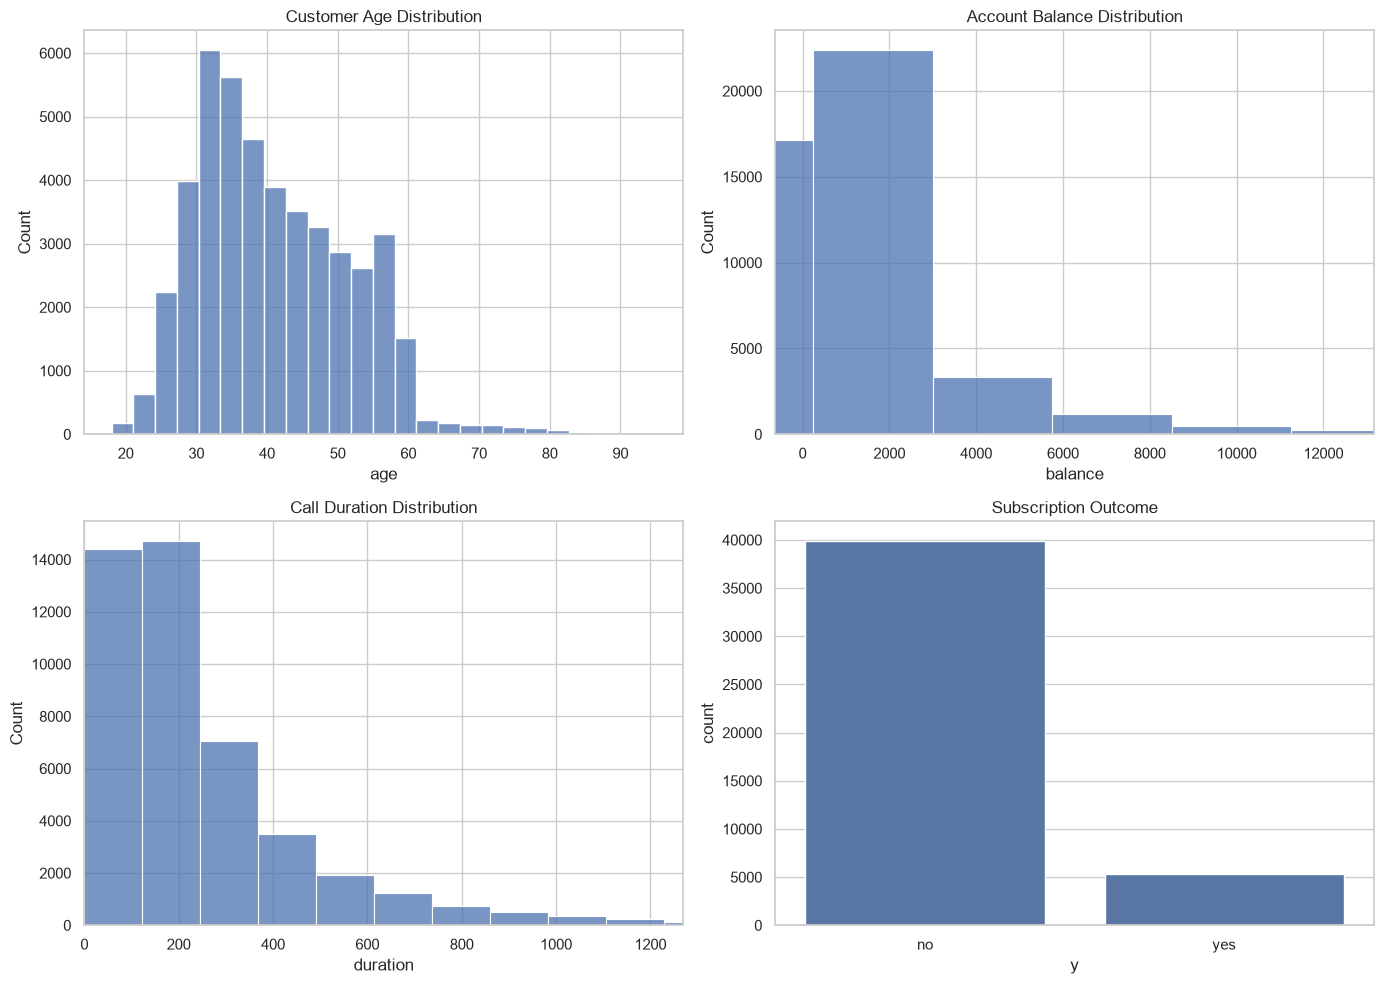

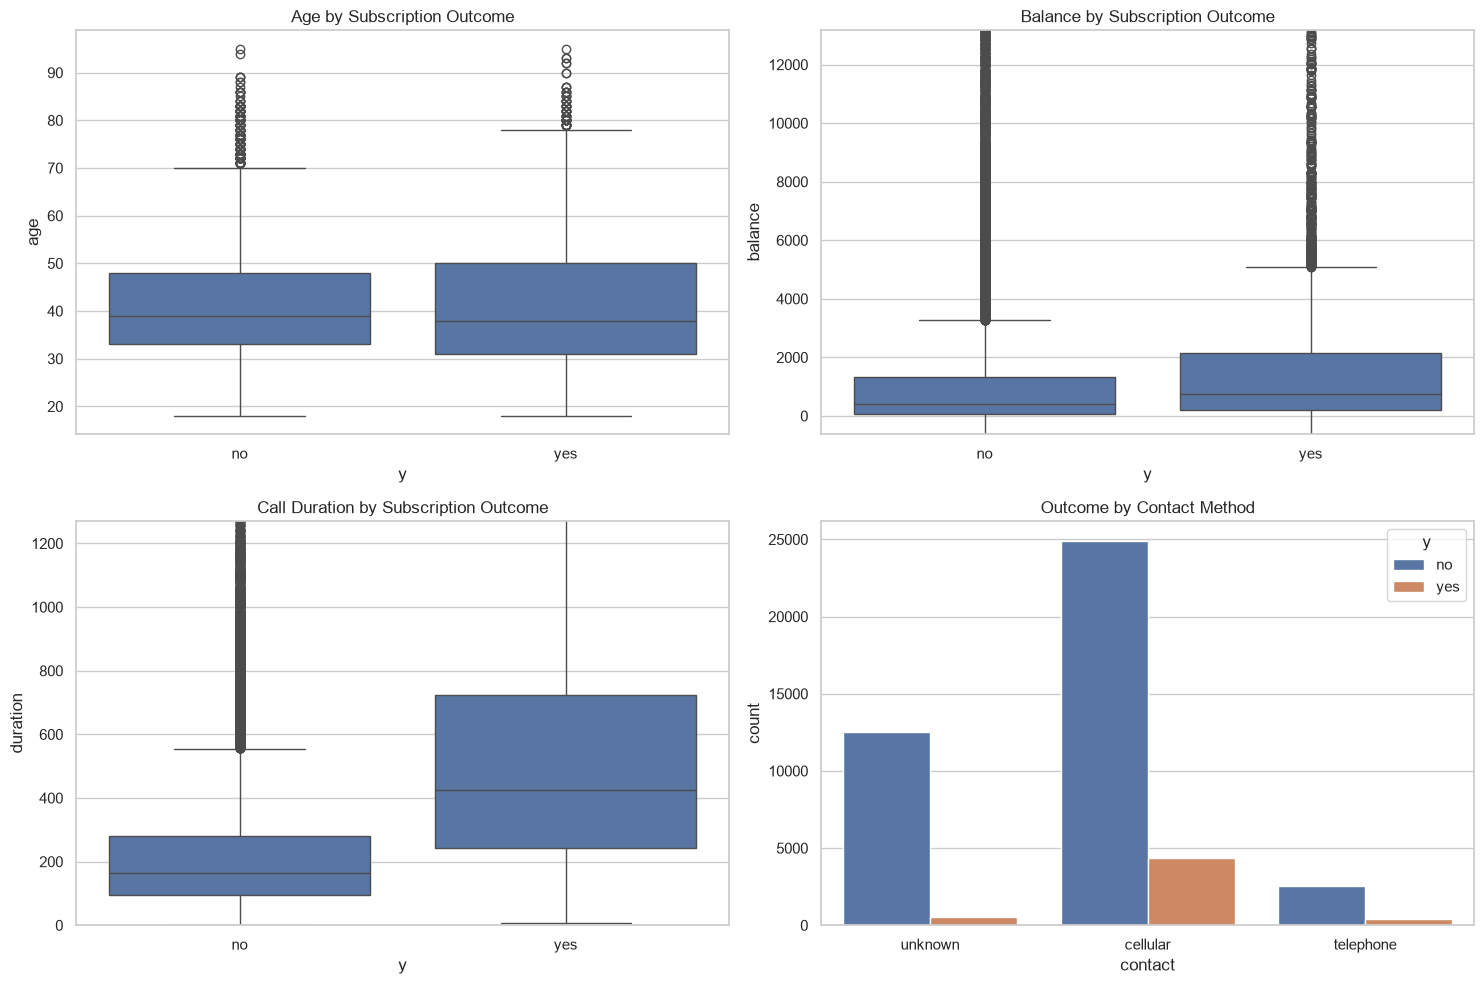

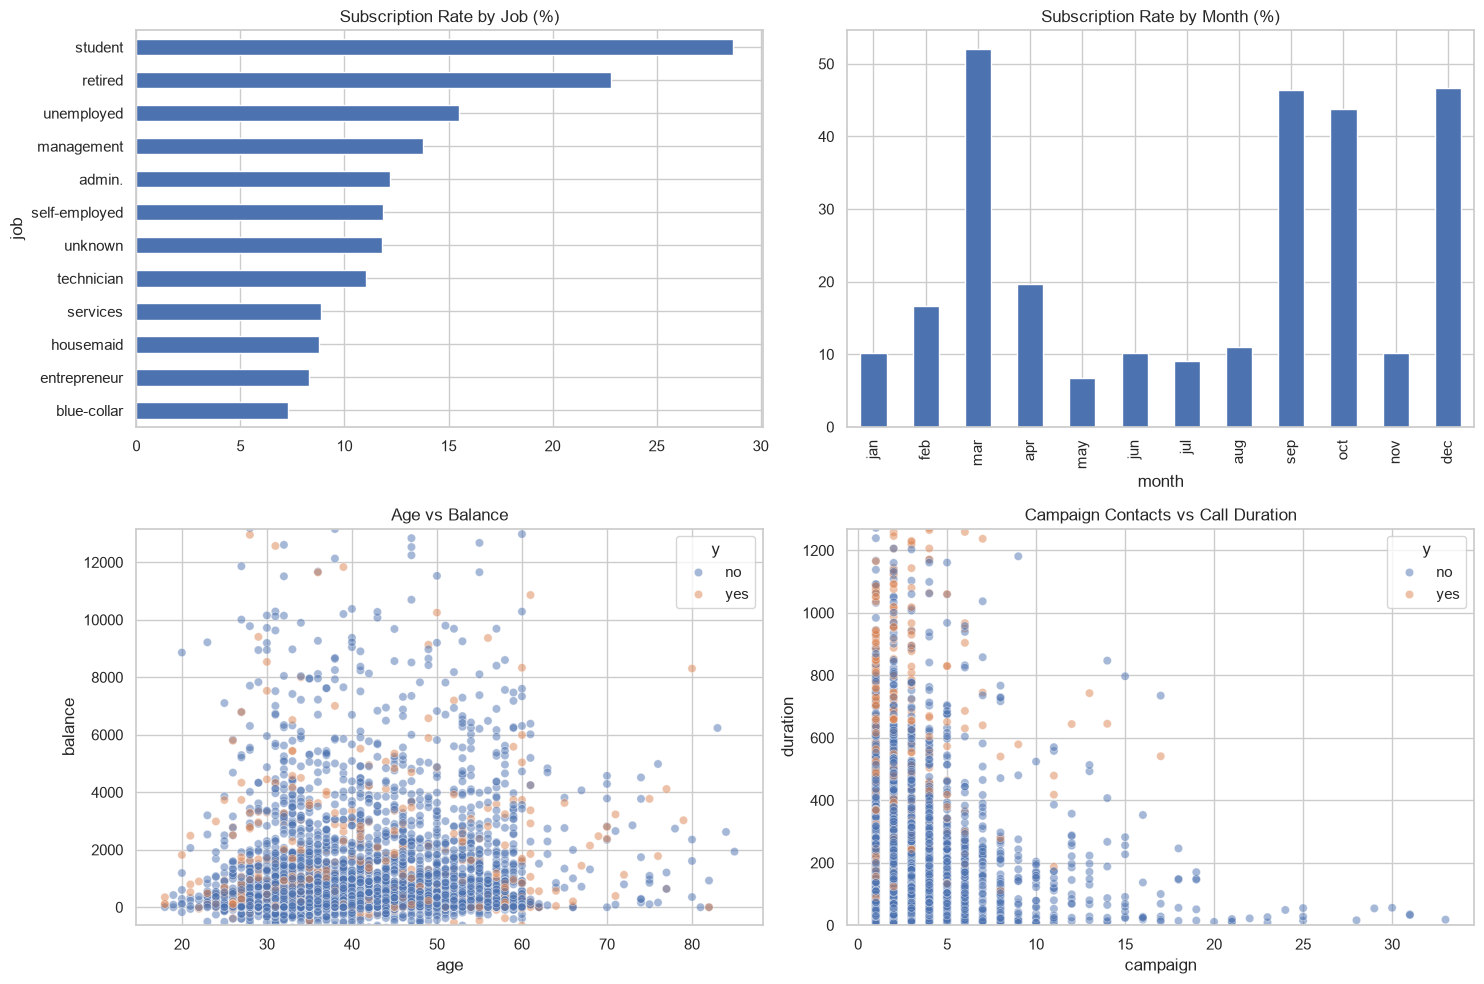

In [3]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(data=bank, x="age", bins=25, ax=axes[0, 0])
axes[0, 0].set_title("Customer Age Distribution")

sns.histplot(data=bank, x="balance", bins=40, ax=axes[0, 1])
axes[0, 1].set_xlim(bank["balance"].quantile(0.01), bank["balance"].quantile(0.99))
axes[0, 1].set_title("Account Balance Distribution")

sns.histplot(data=bank, x="duration", bins=40, ax=axes[1, 0])
axes[1, 0].set_xlim(0, bank["duration"].quantile(0.99))
axes[1, 0].set_title("Call Duration Distribution")

sns.countplot(data=bank, x="y", ax=axes[1, 1])
axes[1, 1].set_title("Subscription Outcome")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(data=bank, x="y", y="age", ax=axes[0, 0])
axes[0, 0].set_title("Age by Subscription Outcome")

sns.boxplot(data=bank, x="y", y="balance", ax=axes[0, 1])
axes[0, 1].set_ylim(bank["balance"].quantile(0.01), bank["balance"].quantile(0.99))
axes[0, 1].set_title("Balance by Subscription Outcome")

sns.boxplot(data=bank, x="y", y="duration", ax=axes[1, 0])
axes[1, 0].set_ylim(0, bank["duration"].quantile(0.99))
axes[1, 0].set_title("Call Duration by Subscription Outcome")

sns.countplot(data=bank, x="contact", hue="y", ax=axes[1, 1])
axes[1, 1].set_title("Outcome by Contact Method")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

job_rates = bank.groupby("job")["subscribed"].mean().mul(100).sort_values()
job_rates.plot(kind="barh", ax=axes[0, 0])
axes[0, 0].set_title("Subscription Rate by Job (%)")

month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]
month_rates = bank.groupby("month")["subscribed"].mean().reindex(month_order).mul(100)
month_rates.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Subscription Rate by Month (%)")

sns.scatterplot(data=bank.sample(4000, random_state=42),
                x="age", y="balance", hue="y", alpha=0.5, ax=axes[1, 0])
axes[1, 0].set_ylim(bank["balance"].quantile(0.01), bank["balance"].quantile(0.99))
axes[1, 0].set_title("Age vs Balance")

sns.scatterplot(data=bank.sample(4000, random_state=42),
                x="campaign", y="duration", hue="y", alpha=0.5, ax=axes[1, 1])
axes[1, 1].set_ylim(0, bank["duration"].quantile(0.99))
axes[1, 1].set_title("Campaign Contacts vs Call Duration")

plt.tight_layout()
plt.show()

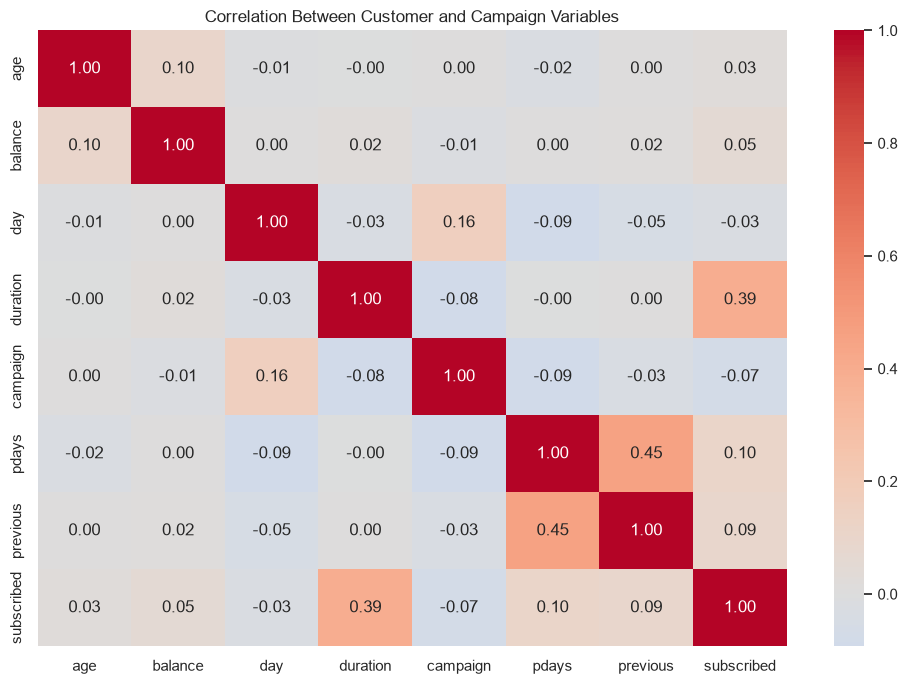

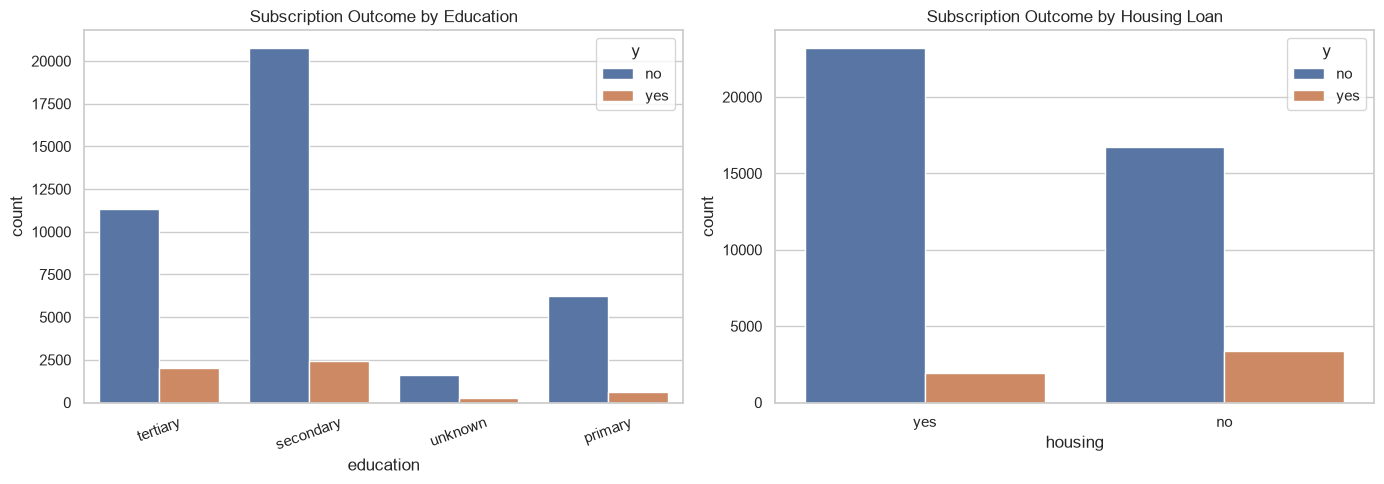

Subscription rate by marital status:


marital
divorced    11.95
married     10.12
single      14.95
Name: subscribed, dtype: float64

Subscription rate by previous campaign outcome:


poutcome
failure    12.61
other      16.68
success    64.73
unknown     9.16
Name: subscribed, dtype: float64

Subscription rate by number of contacts in this campaign:


campaign
1     14.60
2     11.20
3     11.19
4      9.00
5      7.88
6      7.13
7      6.39
8      5.93
9      6.42
10     5.26
Name: subscribed, dtype: float64

In [4]:
numeric_cols = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous", "subscribed"
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    bank[numeric_cols].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Correlation Between Customer and Campaign Variables")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=bank, x="education", hue="y", ax=axes[0])
axes[0].set_title("Subscription Outcome by Education")
axes[0].tick_params(axis="x", rotation=20)

sns.countplot(data=bank, x="housing", hue="y", ax=axes[1])
axes[1].set_title("Subscription Outcome by Housing Loan")

plt.tight_layout()
plt.show()

print("Subscription rate by marital status:")
display((bank.groupby("marital")["subscribed"].mean() * 100).round(2))

print("Subscription rate by previous campaign outcome:")
display((bank.groupby("poutcome")["subscribed"].mean() * 100).round(2))

print("Subscription rate by number of contacts in this campaign:")
display(
    (bank.groupby("campaign")["subscribed"].mean() * 100)
    .round(2).head(10)
)